In [3]:
import pandas as pd
import numpy as np
import yfinance as yf
import seaborn as sns
import matplotlib.pyplot as plt


## Portfolio Diversification

In [4]:
tickers = ["ADBE", "ORCL", "CSCO", "JPM", "GOOGL", "AMZN", "TSLA", "PG", "XOM","SLB"]

df_stocks_prices = yf.download(tickers, period="10y")[["Close"]]
df_stocks_prices.columns = ["ADBE", "ORCL", "CSCO", "JPM", "GOOGL", "AMZN", "TSLA", "PG", "XOM","SLB"]

df_stocks_returns = df_stocks_prices.pct_change(fill_method=None).dropna()

[*********************100%***********************]  10 of 10 completed


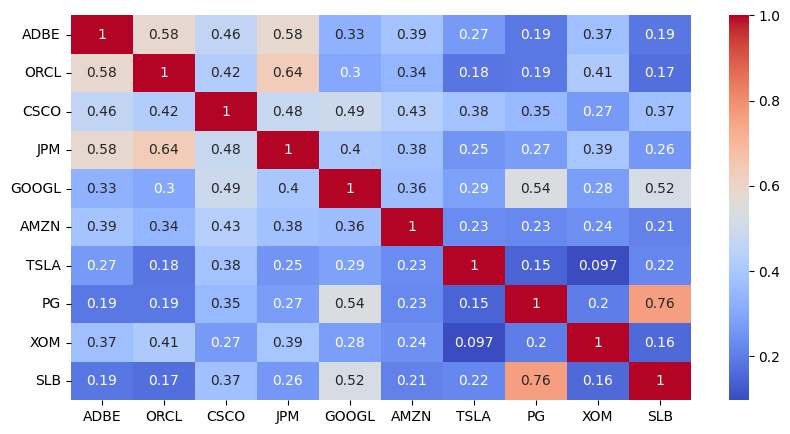

In [8]:
plt.figure(figsize=(10,5))
sns.heatmap(df_stocks_returns.corr(), annot=True, cmap="coolwarm")
plt.show()

In [ ]:
spy = yf.download("SPY", period="10y")["Close"]
spy_returns = spy["SPY"].pct_change(fill_method=None).dropna()

[*********************100%***********************]  1 of 1 completed


In [ ]:
n_stocks = len(df_stocks_returns.columns)
weights = np.array([1/n_stocks] * n_stocks)

print(f"Number of Stocks    : {n_stocks}")
print(f"Weight each Stocks  : {weights[0]:.2f}")
print(f"Total Weights       : {weights.sum()}")

Number of Stocks : 10
Weight each      : 0.10
Total Weights    : 1.0


In [15]:
portfolio_returns = df_stocks_returns.dot(weights)

print(f"Portfolio Mean Daily Return : {portfolio_returns.mean():.4f}")
print(f"Portfolio Std Daily Return  : {portfolio_returns.std():.4f}")

Portfolio Mean Daily Return : 0.0008
Portfolio Std Daily Return  : 0.0131


In [16]:
print(f"Portfolio Daily Return : {portfolio_returns.mean():.4f}")
print(f"SPY Daily Return       : {spy_returns.mean():.4f}")

print(f"\nPortfolio Daily Std : {portfolio_returns.std():.4f}")
print(f"SPY Daily Std       : {spy_returns.std():.4f}")

Portfolio Daily Return : 0.0008
SPY Daily Return       : 0.0006

Portfolio Daily Std : 0.0131
SPY Daily Std       : 0.0113


In [19]:
def sortino_ratio(returns, risk_free_rate=0.0361):
    annual_return = returns.mean() * 252
    downside_std = returns[returns < 0].std() * np.sqrt(252)
    return (annual_return - risk_free_rate) / downside_std

print(f"Portfolio Sortino : {sortino_ratio(portfolio_returns):.2f}")
print(f"SPY Sortino       : {sortino_ratio(spy_returns):.2f}")

Portfolio Sortino : 1.05
SPY Sortino       : 0.78
